## Exploratory Data Analysis (EDA)
Data Source: https://www.nhs.uk/conditions/ \
Raw data: `data/nhs_conditions.jsonl`

This notebook performs an **Exploratory Data Analysis (EDA)** on the medical dataset.  
Goal: ensure the data from web crawling is consistent, complete, and ready for downstream RAG processing (chunking, embedding, etc.).

---

## 1. Import libraries

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

## 2. Load dataset
Data is store in `data/`.

In [32]:
df = pd.read_json("../data/nhs_conditions.jsonl", lines=True)

In [33]:
df.head(10)

,condition,section,url,content
0,Abdominal aortic aneurysm,Symptoms,https://www.nhs.uk/conditions/abdominal-aortic...,Symptoms of abdominal aortic aneurysm\n\nAbdom...
1,Abdominal aortic aneurysm,Treatment,https://www.nhs.uk/conditions/abdominal-aortic...,Treatment for abdominal aortic aneurysm\n\nTre...
2,Acanthosis nigricans,Symptoms,https://www.nhs.uk/conditions/acanthosis-nigri...,Symptoms of acanthosis nigricans\n\nThe main s...
3,Acanthosis nigricans,Treating,https://www.nhs.uk/conditions/acanthosis-nigri...,Treating acanthosis nigricans\n\nOnce a GP kno...
4,Achalasia,Symptoms,https://www.nhs.uk/conditions/achalasia/,Symptoms of achalasia\n\nNot everyone with ach...
5,Achalasia,Treatment,https://www.nhs.uk/conditions/achalasia/,Treatments for achalasia\n\nThere is no cure f...
6,Acid and chemical burns,Treatment,https://www.nhs.uk/conditions/acid-and-chemica...,Treatment for acid and chemical burns\n\nAcid ...
7,Overview - Acne,Symptoms,https://www.nhs.uk/conditions/acne/,Symptoms of acne\n\nAcne most commonly develop...
8,Overview - Acne,treatment,https://www.nhs.uk/conditions/acne/treatment/,Treatment - Acne\n\nTreatment for acne depends...
9,Acoustic neuroma (vestibular schwannoma),Symptoms,https://www.nhs.uk/conditions/acoustic-neuroma/,Symptoms of an acoustic neuroma\n\nAn acoustic...


## 3. Check data

In [34]:
expected_cols = ["condition", "section", "url", "content"]
print("Columns:", df.columns.tolist())

missing_cols = [c for c in expected_cols if c not in df.columns]
if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All expected columns found!")


Columns: ['condition', 'section', 'url', 'content']
All expected columns found!


In [35]:
df.isna().sum()

condition    0
section      0
url          0
content      0
dtype: int64

In [36]:
print("Unique sections:", df['section'].unique().tolist())

Unique sections: ['Symptoms', 'Treatment', 'Treating', 'treatment']


## 4.Standardize `section`

In [37]:
# Convert all 'treat' section to 'Treatment'
df['section'] = df['section'].replace(['Treatment', 'Treating', 'treatment'], 'Treatment')

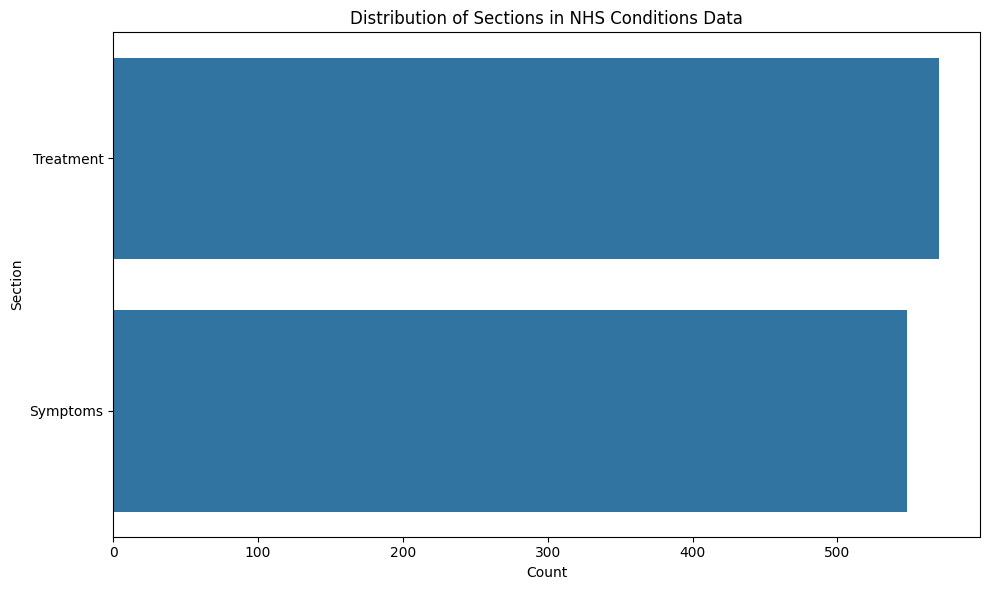

In [38]:
# Visualize the distribution of sections
plt.figure(figsize=(10, 6))
sns.countplot(y='section', data=df, order=df['section'].value_counts().index)
plt.title('Distribution of Sections in NHS Conditions Data')
plt.xlabel('Count')
plt.ylabel('Section')
plt.tight_layout()
plt.show()

Some types of `conditions` don’t have specific symptoms (acid burn, birthmarks,...)

In [39]:
# print sample content from each section
for section in df['section'].unique():
    sample_content = df[df['section'] == section]['content'].iloc[0]
    print(f"\nSection: {section}\nSample Content: {sample_content[:300]}...\n")


Section: Symptoms
Sample Content: Symptoms of abdominal aortic aneurysm

Abdominal aortic aneurysm often has no symptoms.

You usually only find out you have one during an abdominal aortic aneurysm screening test or during tests for another condition.

If an aneurysm gets bigger, you might sometimes notice:

- tummy or back pain

- ...


Section: Treatment
Sample Content: Treatment for abdominal aortic aneurysm

Treatment for an abdominal aortic aneurysm usually depends on how big it is and if you have symptoms.

If it's small, lifestyle changes such as quitting smoking and eating healthily may be recommended to help stop it getting bigger.

Sometimes you may need:

...



## 5.Text statistics
Analyze text length distribution to assess chunking strategy later.

Average length: 289.36940966010735
Median length: 178.0
Max length: 2613


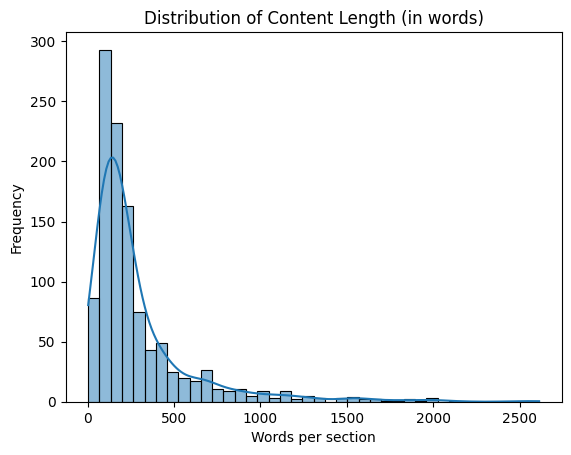

In [40]:
df["content_length"] = df["content"].apply(lambda x: len(x.split()))

print("Average length:", df["content_length"].mean())
print("Median length:", df["content_length"].median())
print("Max length:", df["content_length"].max())

sns.histplot(df["content_length"], bins=40, kde=True)
plt.title("Distribution of Content Length (in words)")
plt.xlabel("Words per section")
plt.ylabel("Frequency")
plt.show()

## 6. Detect duplicates

In [41]:
duplicate_rows = df[df.duplicated(subset=["condition", "section"], keep=False)]
print(f"{len(duplicate_rows)} duplicate section")
display(duplicate_rows.head(5))

24 duplicate section


,condition,section,url,content,content_length
244,Overview - Cleft lip and palate,Treatment,https://www.nhs.uk/conditions/cleft-lip-and-pa...,Treatment\n\nChildren with a cleft lip or pala...,1145
245,Overview - Cleft lip and palate,Treatment,https://www.nhs.uk/conditions/cleft-lip-and-pa...,Treating hearing problems\n\nChildren with a c...,87
315,Overview - Developmental co-ordination disorde...,Treatment,https://www.nhs.uk/conditions/developmental-co...,Treatment for dyspraxia\n\nThere is no cure fo...,269
316,Overview - Developmental co-ordination disorde...,Treatment,https://www.nhs.uk/conditions/developmental-co...,Treating other conditions\n\nChildren with DCD...,200
376,Erectile dysfunction (impotence),Treatment,https://www.nhs.uk/conditions/erection-problem...,Treatments for erectile dysfunction\n\nTreatme...,527


In [42]:
# Drop duplicates and print number of row was removed
initial_len = len(df)
df = df.drop_duplicates(subset=["condition", "section"])
removed_len = initial_len - len(df)
print(f"Removed {removed_len} duplicate rows.")

Removed 12 duplicate rows.


## 7. Standardize condition's name

In [43]:
# Delete word 'Overview - ' from the beginning of content in condition's name
df['condition'] = df['condition'].str.replace(r'^Overview - ', '', regex=True)

In [44]:
df.head(10)

,condition,section,url,content,content_length
0,Abdominal aortic aneurysm,Symptoms,https://www.nhs.uk/conditions/abdominal-aortic...,Symptoms of abdominal aortic aneurysm\n\nAbdom...,66
1,Abdominal aortic aneurysm,Treatment,https://www.nhs.uk/conditions/abdominal-aortic...,Treatment for abdominal aortic aneurysm\n\nTre...,189
2,Acanthosis nigricans,Symptoms,https://www.nhs.uk/conditions/acanthosis-nigri...,Symptoms of acanthosis nigricans\n\nThe main s...,43
3,Acanthosis nigricans,Treatment,https://www.nhs.uk/conditions/acanthosis-nigri...,Treating acanthosis nigricans\n\nOnce a GP kno...,140
4,Achalasia,Symptoms,https://www.nhs.uk/conditions/achalasia/,Symptoms of achalasia\n\nNot everyone with ach...,179
5,Achalasia,Treatment,https://www.nhs.uk/conditions/achalasia/,Treatments for achalasia\n\nThere is no cure f...,438
6,Acid and chemical burns,Treatment,https://www.nhs.uk/conditions/acid-and-chemica...,Treatment for acid and chemical burns\n\nAcid ...,158
7,Acne,Symptoms,https://www.nhs.uk/conditions/acne/,Symptoms of acne\n\nAcne most commonly develop...,73
8,Acne,Treatment,https://www.nhs.uk/conditions/acne/treatment/,Treatment - Acne\n\nTreatment for acne depends...,1464
9,Acoustic neuroma (vestibular schwannoma),Symptoms,https://www.nhs.uk/conditions/acoustic-neuroma/,Symptoms of an acoustic neuroma\n\nAn acoustic...,179


## 8. Preprocessing `content`

In [45]:
def clean_newlines(text):
    text = text.replace('\r\n', '\n')
    text = re.sub(r'\n{2,}', '\n', text)
    text = re.sub(r'[ \t]+', ' ', text)
    return text.strip()

In [46]:
df["content"] = df["content"].apply(clean_newlines)

## 9. Save data

In [47]:
df.to_json("../data/nhs_cleaned.jsonl", lines=True, orient="records", force_ascii=False)